<a href="https://colab.research.google.com/github/ababilkhoerulimam/text-processing-week4/blob/main/ababil%20bethania_exercise%205.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 5 - Feature Engineering

**Chapter 5 - Text Feature Engineering**

Anggota Kelompok (2 mahasiswa):
1. Ababil Khoerul Imam - 152
2. Bethania Putri Junjungsari Nugraha - 115

**Tugas:**
Menerapkan berbagai teknik feature engineering pada data teks hasil preprocessing Exercise 4 (kolom `prepro`) dan menganalisis representasi yang dihasilkan:
1. **One Hot Encoding**
2. **Bag of Words (BoW)**
3. **TF-IDF (Term Frequency - Inverse Document Frequency)**
4. **Word2Vec (CBOW & Skip-Gram)**
5. **FastText**

## 0. Persiapan (Import Library & Unduh Data)

Library yang digunakan:
- `pandas` dan `numpy` untuk manipulasi data dan matriks
- `matplotlib.pyplot` untuk visualisasi
- `scikit-learn` untuk One Hot Encoding, Bag of Words, TF-IDF, PCA, dan cosine similarity
- `nltk` untuk tokenisasi teks
- `gensim` untuk Word2Vec dan FastText

In [1]:
!pip install -q gensim

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
from nltk import word_tokenize

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

import gensim.models

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)

  error: subprocess-exited-with-error
  
  × Building wheel for gensim (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [716 lines of output]
      C:\Users\Hi\AppData\Local\Temp\pip-build-env-ogqxi4k8\overlay\Lib\site-packages\setuptools\_distutils\dist.py:318: UserWarning: Unknown distribution option: 'test_suite'
        warnings.warn(msg)
      C:\Users\Hi\AppData\Local\Temp\pip-build-env-ogqxi4k8\overlay\Lib\site-packages\setuptools\_distutils\dist.py:318: UserWarning: Unknown distribution option: 'tests_require'
        warnings.warn(msg)
      running bdist_wheel
      running build
      running build_py
      creating build\lib.win-amd64-cpython-314\gensim
      copying gensim\downloader.py -> build\lib.win-amd64-cpython-314\gensim
      copying gensim\interfaces.py -> build\lib.win-amd64-cpython-314\gensim
      copying gensim\matutils.py -> build\lib.win-amd64-cpython-314\gensim
      copying gensim\nosy.py -> build\lib.win-amd64-cpython-314\gensim
      cop

### Data yang Digunakan

Teks yang digunakan adalah hasil preprocessing dari Exercise 4, yaitu kolom `prepro`. Setiap baris merepresentasikan satu judul Hacker News yang telah dibersihkan.

In [2]:
try:
    df_pre = df_api['prepro'].dropna().reset_index(drop=True)
except NameError:
    try:
        df = pd.read_csv('hackernews_preprocessed.csv')
    except FileNotFoundError:
        df = pd.read_csv(
            'https://raw.githubusercontent.com/ababilkhoerulimam/text-processing-week4/main/hackernews_preprocessed.csv'
        )
    df = df.dropna().reset_index(drop=True)
    df_pre = df['prepro']

df_pre.head(10)

0                                      pi dev said mcp
1                  sdf vs msdf vs slug gpu text render
2    show hn jbr 001 open sourc 3d printabl desktop...
3                            livenerf opu 5 5 nerf yet
4                                     mathemat origami
5                    could access 17t microsoft record
6                                solv factorio qualiti
7                            get way robot crash cours
8                                      dot alway agent
9              vermont replac power plant home batteri
Name: prepro, dtype: str

In [3]:
n_tokens = df_pre.str.split().str.len()

print(f'Jumlah dokumen        : {len(df_pre)}')
print(f'Total token           : {n_tokens.sum()}')
print(f'Token per dokumen     : min={n_tokens.min()}, mean={n_tokens.mean():.1f}, max={n_tokens.max()}')
print(f'Dokumen kosong        : {(df_pre.str.strip() == "").sum()}')

Jumlah dokumen        : 30
Total token           : 185
Token per dokumen     : min=2, mean=6.2, max=12
Dokumen kosong        : 0


## 1. One Hot Encoding

In [4]:
vectorizer_binary = CountVectorizer(binary=True)
X_ohe = vectorizer_binary.fit_transform(df_pre)

df_onehot = pd.DataFrame(
    X_ohe.toarray(),
    columns=vectorizer_binary.get_feature_names_out()
)

print('Shape:', df_onehot.shape)
df_onehot.head()

Shape: (30, 163)


,001,17t,2026,2d,300,3d,50,526k,71a,access,...,use,vermont,vs,way,webgpu,websit,word,work,world,yet
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Analysis

One Hot Encoding mengubah teks menjadi matriks biner bernilai **0 atau 1**. Nilai `1` menandakan keberadaan suatu kata di dalam dokumen, sedangkan `0` menunjukkan ketiadaannya.

Setiap baris merepresentasikan satu dokumen dan setiap kolom merepresentasikan satu kata unik dari vocabulary. Representasi ini tidak memperhitungkan frekuensi kemunculan kata jika kata tersebut muncul lebih dari sekali dalam satu dokumen.

## 2. Bag of Words

In [5]:
vectorizer_bow = CountVectorizer()
X_bow = vectorizer_bow.fit_transform(df_pre)

df_bow = pd.DataFrame(
    X_bow.toarray(),
    columns=vectorizer_bow.get_feature_names_out()
)

print('Shape:', df_bow.shape)
df_bow.head()

Shape: (30, 163)


,001,17t,2026,2d,300,3d,50,526k,71a,access,...,use,vermont,vs,way,webgpu,websit,word,work,world,yet
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,2,0,0,0,0,0,0,0
2,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Analysis

Bag of Words (BoW) merepresentasikan teks sebagai matriks frekuensi kemunculan kata (*term frequency*). Berbeda dengan One Hot Encoding yang hanya bernilai biner, BoW mencatat berapa kali suatu kata muncul di dalam masing-masing dokumen.

Jika suatu kata muncul lebih dari satu kali dalam suatu judul, nilai pada elemen matriks tersebut akan lebih dari `1`.

In [6]:
print('One Hot == BoW ?', (X_ohe != X_bow).nnz == 0)

doc_freq = np.asarray((X_ohe > 0).sum(axis=0)).ravel()
df_stats = pd.DataFrame({
    'term': vectorizer_binary.get_feature_names_out(),
    'doc_freq': doc_freq
})

print(f'Kata muncul di >1 dokumen : {(doc_freq > 1).sum()} dari {len(doc_freq)}')
print(f'Kata muncul di 1 dokumen  : {(doc_freq == 1).sum()} dari {len(doc_freq)}')

df_stats.sort_values('doc_freq', ascending=False).head(10).reset_index(drop=True)

One Hot == BoW ? False
Kata muncul di >1 dokumen : 9 dari 163
Kata muncul di 1 dokumen  : 154 dari 163


,term,doc_freq
0,hn,4
1,show,3
2,2026,2
3,languag,2
4,text,2
5,robot,2
6,price,2
7,ask,2
8,qualiti,2
9,17t,1


## 3. TF-IDF

In [7]:
vectorizer_tfidf = TfidfVectorizer()
X_tfidf = vectorizer_tfidf.fit_transform(df_pre)
terms = vectorizer_tfidf.get_feature_names_out()

df_tfidf = pd.DataFrame(
    X_tfidf.toarray(),
    columns=terms
)

print('Shape:', df_tfidf.shape)
df_tfidf.round(2).head()

Shape: (30, 163)


,001,17t,2026,2d,300,3d,50,526k,71a,access,...,use,vermont,vs,way,webgpu,websit,word,work,world,yet
0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.00,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.0,0.0,0.64,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.33,0.0,0.0,0.0,0.0,0.33,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.00,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.5
4,0.00,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Analysis

TF-IDF (Term Frequency - Inverse Document Frequency) memberikan bobot numerik pada setiap kata berdasarkan frekuensi relatif kemunculannya di dokumen terhadap seluruh korpus.

Kata yang muncul di banyak dokumen (seperti `hn` atau `show`) akan mendapatkan nilai IDF lebih rendah karena kurang diskriminatif, sedangkan kata yang hanya muncul di sedikit dokumen spesifik akan memiliki bobot yang lebih tinggi.

In [8]:
idf = pd.Series(vectorizer_tfidf.idf_, index=terms).sort_values()

print('IDF terendah (kata yang lebih umum):')
print(idf.head(6).round(3).to_string())

print('\nIDF tertinggi (kata yang lebih jarang):')
print(idf.tail(3).round(3).to_string())

IDF terendah (kata yang lebih umum):
hn         2.825
show       3.048
languag    3.335
2026       3.335
price      3.335
qualiti    3.335

IDF tertinggi (kata yang lebih jarang):
work     3.741
world    3.741
yet      3.741


### Analisis representasi One Hot, BoW, dan TF-IDF

In [9]:
rows = []

for name, X in [
    ('One Hot', X_ohe),
    ('Bag of Words', X_bow),
    ('TF-IDF', X_tfidf)
]:
    total = X.shape[0] * X.shape[1]
    rows.append({
        'Metode': name,
        'Dokumen': X.shape[0],
        'Fitur': X.shape[1],
        'Nilai non-nol': X.nnz,
        'Sparsity (%)': round(100 * (1 - X.nnz / total), 2),
        'Nilai maks': round(float(X.max()), 3)
    })

pd.DataFrame(rows)

,Metode,Dokumen,Fitur,Nilai non-nol,Sparsity (%),Nilai maks
0,One Hot,30,163,175,96.42,1.000
1,Bag of Words,30,163,175,96.42,2.000
2,TF-IDF,30,163,175,96.42,0.707


Pada dataset ini, jumlah fitur jauh lebih besar dibandingkan jumlah nilai yang terisi, menghasilkan matriks dengan tingkat sparsity >96%. Hal ini wajar untuk korpus teks pendek.

Perbedaan One Hot dan BoW hanya terletak pada kata yang berulang dalam satu dokumen (seperti kata `vs` pada judul kedua).

## 4. Word2Vec

In [10]:
sentences = [word_tokenize(text.lower()) for text in df_pre]
sentences[:5]

[['pi', 'dev', 'said', 'mcp'],
 ['sdf', 'vs', 'msdf', 'vs', 'slug', 'gpu', 'text', 'render'],
 ['show',
  'hn',
  'jbr',
  '001',
  'open',
  'sourc',
  '3d',
  'printabl',
  'desktop',
  'robot'],
 ['livenerf', 'opu', '5', '5', 'nerf', 'yet'],
 ['mathemat', 'origami']]

In [11]:
model = gensim.models.Word2Vec(
    sentences,
    min_count=1,
    vector_size=100,
    window=5,
    sg=0,
    epochs=10,
    seed=42,
    workers=1
)

w2v = model.wv

print('Jumlah vocabulary:', len(w2v.index_to_key))
print('10 kata pertama:', w2v.index_to_key[:10])
print('Ukuran vector:', w2v.vector_size)

Jumlah vocabulary: 167
10 kata pertama: ['hn', '1', '5', 'show', 'languag', 'price', '2026', 'u', 'ask', 'qualiti']
Ukuran vector: 100


Parameter yang digunakan:

- `min_count=1` → seluruh kata yang muncul minimal 1 kali diikutsertakan.
- `vector_size=100` → dimensi ruang embedding setiap kata.
- `window=5` → lebar konteks sekitar kata target.
- `sg=0` → arsitektur Continuous Bag of Words (CBOW).
- `epochs=10` → iterasi pelatihan embedding.

In [12]:
word_example = w2v.index_to_key[0]

print('Kata:', word_example)
print('Vector:')
print(w2v[word_example])

if 'data' in w2v:
    print('\nKata yang paling mirip dengan data:')
    print(w2v.most_similar('data', topn=5))

Kata: hn
Vector:
[-8.1371162e-03  5.4649431e-03  3.0762723e-03 -1.2310187e-03
 -1.3203926e-03  7.1799280e-03 -8.2127312e-03  3.9997832e-03
 -6.0592955e-03 -8.1342459e-03  4.9578020e-04  9.5619010e-03
  4.6948432e-03  5.3125466e-03  4.3978314e-03  5.6654052e-03
  2.6480824e-04 -7.4725249e-03  6.7057069e-03 -1.0048411e-03
  1.5626447e-05 -2.5696619e-03 -6.2947334e-03  8.5606342e-03
  5.6658234e-03  2.8780417e-03 -2.0137560e-03  6.4517185e-03
  8.4639160e-04 -1.2154164e-03 -1.0065216e-03 -5.5116178e-03
 -8.1020715e-03  1.0848982e-03  7.7209552e-03 -8.6645111e-03
  7.1499851e-03  6.5047313e-03 -4.3935990e-03  2.6600312e-03
 -6.6261925e-03  5.1598917e-03  4.1124234e-03 -2.9441952e-03
 -8.6225355e-03  9.3441969e-03 -1.0546442e-03  7.9495087e-03
  3.6083909e-03  5.5490602e-03  5.1842020e-03 -6.2345657e-03
 -2.7202920e-03 -6.7018421e-04 -5.1277202e-06 -9.1457199e-03
  8.8320131e-04 -6.8411962e-03  4.8396946e-03  3.7157789e-03
  8.4313452e-03  4.9100933e-03 -2.7039747e-03  9.3519017e-03
 -1.734

In [13]:
def get_document_vector(tokens, wv):
    valid_vectors = [wv[word] for word in tokens if word in wv]
    return np.mean(valid_vectors, axis=0) if valid_vectors else np.zeros(wv.vector_size)

X_w2v = np.array([
    get_document_vector(doc, w2v)
    for doc in sentences
])

df_w2v = pd.DataFrame(X_w2v)

print('Shape fitur dokumen Word2Vec:', X_w2v.shape)
df_w2v.iloc[:, :8].round(3).head()

Shape fitur dokumen Word2Vec: (30, 100)


,0,1,2,3,4,5,6,7
0,0.002,-0.002,-0.007,0.000,0.006,-0.001,0.002,0.004
1,0.006,-0.001,0.004,0.002,0.003,0.004,-0.003,0.001
2,-0.000,0.004,-0.000,0.003,-0.001,0.001,0.003,0.000
3,-0.002,0.000,0.001,-0.000,-0.002,-0.002,0.001,0.004
4,-0.002,-0.000,0.003,0.002,-0.006,0.007,0.003,0.001


### Analysis

Word2Vec memetakan kata ke dalam ruang vektor kontinu 100 dimensi berdasar konteks distribusional.

Untuk memperoleh representasi dokumen/judul utuh, vektor kata dalam setiap dokumen digabungkan melalui *mean pooling*. Hasil akhirnya adalah vektor padat (*dense vector*) 100 dimensi per dokumen.

### Pembanding: Word2Vec Skip-Gram

In [14]:
sg_model = gensim.models.Word2Vec(
    sentences,
    min_count=1,
    vector_size=100,
    window=5,
    sg=1,
    epochs=10,
    seed=42,
    workers=1
)

X_sg = np.array([
    get_document_vector(doc, sg_model.wv)
    for doc in sentences
])

print('Shape:', X_sg.shape)

if 'data' in sg_model.wv:
    print(sg_model.wv.most_similar('data', topn=5))

Shape: (30, 100)
[('526k', 0.21360984444618225), ('microsoft', 0.2097761482000351), ('emu', 0.20709842443466187), ('alway', 0.19957153499126434), ('one', 0.19771422445774078)]


## 5. FastText

In [15]:
model_fasttext = gensim.models.FastText(
    sentences,
    min_count=1,
    vector_size=100,
    window=5,
    min_n=3,
    max_n=6,
    sg=1,
    epochs=10,
    seed=42,
    workers=1
)

ft = model_fasttext.wv

print('Jumlah vocabulary:', len(ft.index_to_key))
print('10 kata pertama:', ft.index_to_key[:10])
print('Ukuran vector:', ft.vector_size)

Jumlah vocabulary: 167
10 kata pertama: ['hn', '1', '5', 'show', 'languag', 'price', '2026', 'u', 'ask', 'qualiti']
Ukuran vector: 100


Parameter yang digunakan:

- `min_count=1` → seluruh kata tetap digunakan.
- `vector_size=100` → dimensi vektor kata.
- `window=5` → rentang konteks 5 kata.
- `min_n=3` dan `max_n=6` → rentang panjang karakter n-gram (subword).
- `sg=1` → arsitektur Skip-Gram dengan subword information.
- `epochs=10` → iterasi pelatihan disamakan dengan Word2Vec.

In [16]:
word_example = ft.index_to_key[0]

print('Kata:', word_example)
print('Vector:')
print(ft[word_example])

if 'data' in ft:
    print('\nKata yang paling mirip dengan data:')
    print(ft.most_similar('data', topn=5))

Kata: hn
Vector:
[-7.9204008e-04  1.6145074e-03  1.4650298e-03  5.3789315e-04
  3.8937903e-03  9.6292316e-04 -6.2585152e-03 -1.1839115e-03
 -2.0787404e-03 -3.4067326e-03 -3.9177961e-03  3.2664014e-03
  2.4264236e-03  2.1484559e-03  1.0160302e-03 -6.4111932e-04
  1.6889712e-03  2.5795544e-03  4.1815257e-03  1.8658281e-03
  3.2082060e-03 -2.3100583e-03 -2.3079517e-03 -2.6820228e-05
  1.0040321e-04 -3.8584752e-05 -7.7088014e-04  5.8749146e-03
  4.0494874e-03 -2.2147279e-03 -2.7585132e-03  2.7557730e-03
  1.6814619e-03  8.5096457e-04  7.9574471e-04 -1.7310845e-03
  7.0632380e-03  1.5570425e-03 -4.1781459e-03  6.8588275e-03
 -3.8842361e-03 -3.1803525e-03 -2.5716969e-03 -3.5550017e-03
 -3.1561228e-03  1.9434391e-03 -6.9569016e-04  8.4815156e-03
 -1.0357294e-03  3.3226196e-04  5.1183463e-03 -1.0197631e-03
 -1.9221136e-03  3.6966384e-03 -2.3398744e-03 -2.0321808e-03
  7.9195213e-04  4.4566253e-04  7.2986893e-03 -3.8871714e-03
  2.6372620e-03 -2.0423117e-03  1.5335919e-03  1.1619336e-03
  1.477

In [17]:
X_ft = np.array([
    get_document_vector(doc, ft)
    for doc in sentences
])

df_fasttext = pd.DataFrame(X_ft)

print('Shape fitur dokumen FastText:', X_ft.shape)
df_fasttext.iloc[:, :8].round(3).head()

Shape fitur dokumen FastText: (30, 100)


,0,1,2,3,4,5,6,7
0,0.002,0.000,-0.002,-0.001,0.001,-0.001,-0.002,0.001
1,0.003,-0.001,-0.000,0.001,0.001,0.001,0.000,0.002
2,-0.000,0.000,0.000,0.000,0.002,-0.000,0.000,0.000
3,0.001,0.002,0.001,0.002,0.002,-0.001,0.001,0.003
4,-0.001,-0.000,0.001,-0.001,-0.000,-0.001,0.002,-0.001


### Analysis

FastText memperluas Word2Vec dengan memecah kata menjadi *character n-grams* (subword). Model ini mengakumulasikan representasi subword untuk menyusun representasi kata.

Kelebihan utama subword adalah kemampuannya merepresentasikan variasi morfologi dan kata yang tidak ada di kamus pelatihan (*out-of-vocabulary*).

In [18]:
oov = 'robotics'

print(f"'{oov}' ada di vocabulary Word2Vec?", oov in w2v)
print(f"'{oov}' ada di vocabulary FastText?", oov in ft.key_to_index)

if oov not in w2v:
    try:
        w2v[oov]
    except KeyError:
        print('Word2Vec -> tidak dapat membuat vector untuk kata OOV')

print(f'Ukuran vector FastText untuk {oov}: {ft[oov].shape}')

'robotics' ada di vocabulary Word2Vec? False
'robotics' ada di vocabulary FastText? False
Word2Vec -> tidak dapat membuat vector untuk kata OOV
Ukuran vector FastText untuk robotics: (100,)


## 6. Visualisasi Embedding Kata

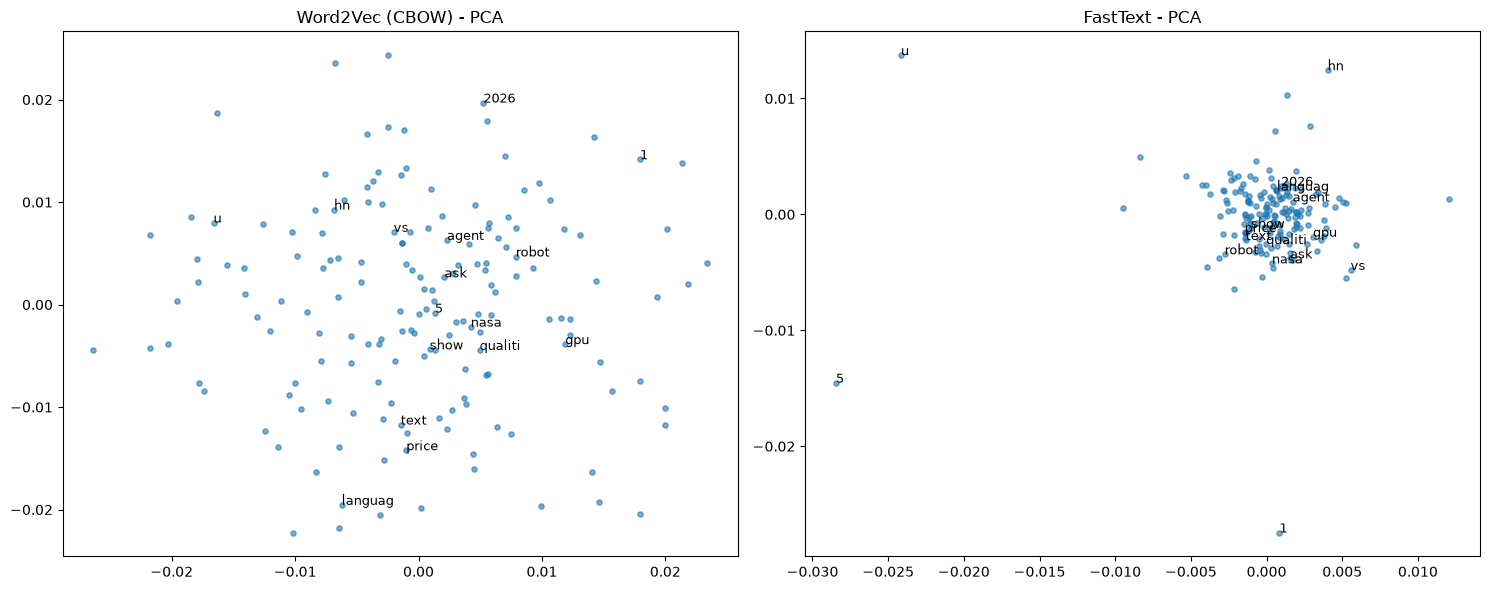

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, wv, title in [
    (axes[0], w2v, 'Word2Vec (CBOW)'),
    (axes[1], ft, 'FastText')
]:
    emb = PCA(n_components=2, random_state=42).fit_transform(wv.vectors)

    ax.scatter(emb[:, 0], emb[:, 1], s=14, alpha=0.6)

    for (x, y), w in zip(emb, wv.index_to_key):
        if wv.get_vecattr(w, 'count') > 1 or w in ('robot', 'agent', 'nasa', 'gpu'):
            ax.annotate(w, (x, y), fontsize=9)

    ax.set_title(f'{title} - PCA')

plt.tight_layout()
plt.show()

## 7. Eksperimen Jumlah Epoch

In [20]:
def avg_pairwise_cos(wv):
    S = cosine_similarity(wv.vectors)
    n = len(S)
    return (S.sum() - n) / (n * n - n)

rows = []

for ep in [5, 20, 50, 100, 200]:
    m_cbow = gensim.models.Word2Vec(
        sentences, min_count=1, vector_size=100,
        window=5, sg=0, epochs=ep, seed=42, workers=1
    )

    m_sg = gensim.models.Word2Vec(
        sentences, min_count=1, vector_size=100,
        window=5, sg=1, epochs=ep, seed=42, workers=1
    )

    m_ft = gensim.models.FastText(
        sentences, min_count=1, vector_size=100,
        window=5, min_n=3, max_n=6, sg=1,
        epochs=ep, seed=42, workers=1
    )

    rows.append({
        'epochs': ep,
        'W2V CBOW': round(avg_pairwise_cos(m_cbow.wv), 2),
        'W2V Skip-Gram': round(avg_pairwise_cos(m_sg.wv), 2),
        'FastText': round(avg_pairwise_cos(m_ft.wv), 2)
    })

sweep = pd.DataFrame(rows).set_index('epochs')

print('Rata-rata cosine similarity antar semua pasangan kata:')
sweep

Rata-rata cosine similarity antar semua pasangan kata:


,W2V CBOW,W2V Skip-Gram,FastText
epochs,,,
5,-0.00,-0.00,0.00
20,0.00,0.01,0.02
50,0.02,0.11,0.36
100,0.20,0.88,0.99
200,0.96,0.98,0.99


### Analysis

Eksperimen ini mengevaluasi dinamika representasi vektor saat jumlah epoch ditingkatkan. Pada korpus berukuran sangat kecil (30 judul), peningkatan epoch berlebih memicu *representation collapse* atau overfitting, di mana kemiripan kosinus antar kata melonjak mendekati 1.0 (vektor menjadi hampir kolinear/seragam).

## 8. Perbandingan Hasil Feature Engineering

In [21]:
summary = pd.DataFrame([
    {
        'Representasi': 'One Hot',
        'Dimensi': X_ohe.shape[1],
        'Tipe': 'sparse',
        'Sparsity (%)': round(100 * (1 - X_ohe.nnz / np.prod(X_ohe.shape)), 1)
    },
    {
        'Representasi': 'Bag of Words',
        'Dimensi': X_bow.shape[1],
        'Tipe': 'sparse',
        'Sparsity (%)': round(100 * (1 - X_bow.nnz / np.prod(X_bow.shape)), 1)
    },
    {
        'Representasi': 'TF-IDF',
        'Dimensi': X_tfidf.shape[1],
        'Tipe': 'sparse',
        'Sparsity (%)': round(100 * (1 - X_tfidf.nnz / np.prod(X_tfidf.shape)), 1)
    },
    {
        'Representasi': 'Word2Vec (CBOW)',
        'Dimensi': X_w2v.shape[1],
        'Tipe': 'dense',
        'Sparsity (%)': 0.0
    },
    {
        'Representasi': 'W2V Skip-Gram',
        'Dimensi': X_sg.shape[1],
        'Tipe': 'dense',
        'Sparsity (%)': 0.0
    },
    {
        'Representasi': 'FastText',
        'Dimensi': X_ft.shape[1],
        'Tipe': 'dense',
        'Sparsity (%)': 0.0
    }
])

summary

,Representasi,Dimensi,Tipe,Sparsity (%)
0,One Hot,163,sparse,96.4
1,Bag of Words,163,sparse,96.4
2,TF-IDF,163,sparse,96.4
3,Word2Vec (CBOW),100,dense,0.0
4,W2V Skip-Gram,100,dense,0.0
5,FastText,100,dense,0.0


### Analisis

Perbandingan karakteristik representasi:
- **One Hot Encoding**: Matriks biner sparse, hanya merekam ada/tidaknya kata.
- **Bag of Words**: Matriks frekuensi sparse, merekam jumlah kemunculan kata per dokumen.
- **TF-IDF**: Matriks terbobot sparse, menyeimbangkan frekuensi lokal dengan kelangkaan global.
- **Word2Vec**: Representasi dense berdimensi tetap (100) yang menangkap relasi semantik konteks kata.
- **FastText**: Representasi dense berdimensi tetap (100) yang memanfaatkan informasi subword n-gram sehingga tahan terhadap kata OOV.

### Perbandingan Kemiripan Dokumen

In [22]:
matrices = {
    'TF-IDF': X_tfidf.toarray(),
    'W2V CBOW': X_w2v,
    'W2V SG': X_sg,
    'FastText': X_ft
}

def neighbours(q, k=3):
    print(f'QUERY: {df_pre.iloc[q]}\n')

    for name, M in matrices.items():
        s = cosine_similarity(M[q:q+1], M).ravel()
        order = [i for i in np.argsort(-s) if i != q][:k]

        print(f'[{name}]')
        for i in order:
            print(f'   {s[i]:.2f}  {df_pre.iloc[i][:70]}')
        print()

neighbours(2)

QUERY: show hn jbr 001 open sourc 3d printabl desktop robot

[TF-IDF]
   0.14  show hn real time solar system 526k asteroid track satellit
   0.12  show hn use 2d dft dither etc maxim eink manga imag qualiti
   0.12  ask hn read

[W2V CBOW]
   0.31  ask hn read
   0.15  nrc issu first u construct permit bwrx 300 small modular reactor
   0.13  septemb 2026 world today seen one polish guy

[W2V SG]
   0.31  ask hn read
   0.17  nrc issu first u construct permit bwrx 300 small modular reactor
   0.14  septemb 2026 world today seen one polish guy

[FastText]
   0.33  show hn real time solar system 526k asteroid track satellit
   0.28  ask hn read
   0.23  show hn use 2d dft dither etc maxim eink manga imag qualiti



## Conclusion

Feature engineering berhasil mentransformasikan teks judul Hacker News yang telah diproses pada Exercise 4 menjadi berbagai representasi numerik: **One Hot Encoding, Bag of Words, TF-IDF, Word2Vec (CBOW & Skip-Gram), dan FastText**.

1. Representasi berbasis frekuensi/vocabulary (OHE, BoW, TF-IDF) menghasilkan matriks sparse dengan dimensi 163 (sesuai jumlah fitur unik non-karakter tunggal). TF-IDF paling informatif di kelompok ini karena mendiskon kata umum korpus.
2. Representasi berbasis embedding (Word2Vec, FastText) menghasilkan vektor dense 100 dimensi yang di-pooling per dokumen. FastText memiliki ketahanan terbaik terhadap variasi morfologi dan kata baru melalui mekanisme subword n-gram.
3. Pada korpus kecil (30 dokumen), representasi leksikal seperti TF-IDF lebih stabil dan mudah diinterpretasikan, sedangkan model berbasis neural embedding memerlukan data yang lebih besar agar bobot semantik tergeneralisasi secara optimal tanpa risiko representation collapse pada epoch tinggi.